## Text Preprocessing ( Tokenization and Normalization )

In [ ]:
import nltk

In [ ]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
text = """
The stock market saw a significant dip today. Experts believe the downturn may continue.
However, many investors are optimistic about future growth.
"""

tokenized_sentences = nltk.sent_tokenize(text)
tokenized_words = [nltk.word_tokenize(sentence) for sentence in tokenized_sentences]
print(tokenized_sentences)
print(tokenized_words)

['\nThe stock market saw a significant dip today.', 'Experts believe the downturn may continue.', 'However, many investors are optimistic about future growth.']
[['The', 'stock', 'market', 'saw', 'a', 'significant', 'dip', 'today', '.'], ['Experts', 'believe', 'the', 'downturn', 'may', 'continue', '.'], ['However', ',', 'many', 'investors', 'are', 'optimistic', 'about', 'future', 'growth', '.']]


In [ ]:
from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
stop_words = stopwords.words('english')
print(stop_words)
#len(stop_words) # 198 English stopwords

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [ ]:
text = ' This is an example to demonstrate the removal of stop words from a sentence .'
tokens = nltk.word_tokenize(text)
tokens

['This',
 'is',
 'an',
 'example',
 'to',
 'demonstrate',
 'the',
 'removal',
 'of',
 'stop',
 'words',
 'from',
 'a',
 'sentence',
 '.']

In [ ]:
filtered_tokens = [word for word in tokens if word.lower() not in stop_words]
filtered_tokens

['example', 'demonstrate', 'removal', 'stop', 'words', 'sentence', '.']

In [ ]:
import string

clean_tokens = [word for word in filtered_tokens if word not in string.punctuation]
lean_tokens

In [ ]:
text = """Data scientists and DATA Engineers need data"""
lower_text = text.lower()
lower_text

'data scientists and data engineers need data'

In [ ]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()
tokens = ['running','bats','organizations','reading']
stemmed_tokens = [stemmer.stem(word) for word in tokens]
stemmed_tokens

['run', 'bat', 'organ', 'read']

In [ ]:
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
tokens = ['running','bats','organizations','reading']
lemmatizer = WordNetLemmatizer()
lemmatized_tokens = [lemmatizer.lemmatize(word) for word in tokens]
lemmatized_tokens

['running', 'bat', 'organization', 'reading']

## Bag of Words Representation (BOW)

In [ ]:
reviews = [
    'I loved the book. It was amazing.',
    'The book was okay.',
    'I hated the book , it was boring.'
]

In [ ]:
def preprocess_text(text):
    text = text.lower()
    tokens = nltk.word_tokenize(text)
    tokens = [word for word in tokens if word not in string.punctuation]
    return " ".join(tokens)

cleaned_reviews = [preprocess_text(review) for review in reviews]
cleaned_reviews

['i loved the book it was amazing',
 'the book was okay',
 'i hated the book it was boring']

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()
bow_vectorizer = vectorizer.fit(cleaned_reviews)
print(vectorizer.get_feature_names_out()) # get vocab words


['amazing' 'book' 'boring' 'hated' 'it' 'loved' 'okay' 'the' 'was']


In [ ]:
bow_matrix = vectorizer.fit_transform(cleaned_reviews)
print(bow_matrix.toarray())

[[1 1 0 0 1 1 0 1 1]
 [0 1 0 0 0 0 1 1 1]
 [0 1 1 1 1 0 0 1 1]]


In [ ]:
import numpy as np

word_counts = np.sum(bow_matrix.toarray(), axis=0)
word_counts

array([1, 3, 1, 1, 2, 1, 1, 3, 3])

In [ ]:
word_labels = vectorizer.get_feature_names_out()
word_labels

array(['amazing', 'book', 'boring', 'hated', 'it', 'loved', 'okay', 'the',
       'was'], dtype=object)

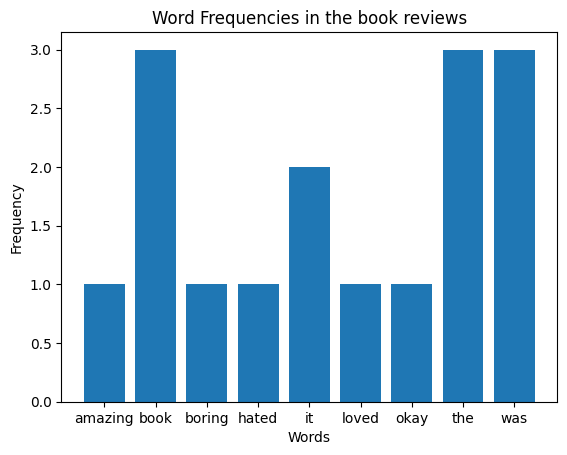

In [ ]:
import matplotlib.pyplot as plt
plt.bar(word_labels, word_counts)
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.title('Word Frequencies in the book reviews')
plt.show()

## TF-IDF WITH BOW Representation

In [ ]:
reviews = [
    'I loved the book. It was amazing.',
    'The book was okay.',
    'I hated the book , it was boring.'
]

In [ ]:
cleaned_reviews = [preprocess_text(review) for review in reviews]
cleaned_reviews

['i loved the book it was amazing',
 'the book was okay',
 'i hated the book it was boring']

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tdif_vectorizer = TfidfVectorizer()
tdif_matrix = tdif_vectorizer.fit_transform(cleaned_reviews)
print(tdif_matrix.toarray(),end='\n\n')
print(tdif_vectorizer.get_feature_names_out())

[[0.52523431 0.31021184 0.         0.         0.39945423 0.52523431
  0.         0.31021184 0.31021184]
 [0.         0.41285857 0.         0.         0.         0.
  0.69903033 0.41285857 0.41285857]
 [0.         0.31021184 0.52523431 0.52523431 0.39945423 0.
  0.         0.31021184 0.31021184]]

['amazing' 'book' 'boring' 'hated' 'it' 'loved' 'okay' 'the' 'was']


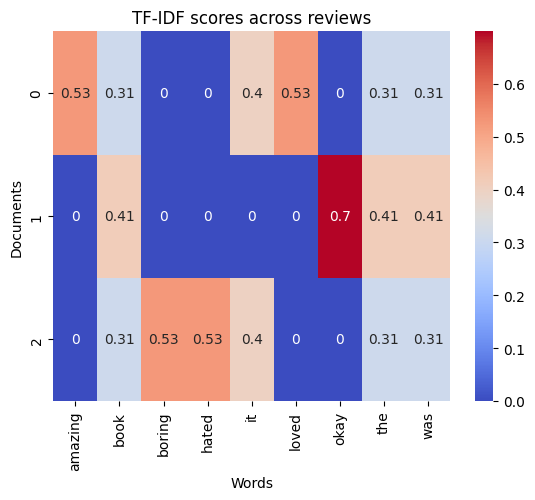

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_tfidf = pd.DataFrame(tdif_matrix.toarray(), columns=tdif_vectorizer.get_feature_names_out())
sns.heatmap(df_tfidf, annot=True, cmap='coolwarm')
plt.title('TF-IDF scores across reviews')
plt.xlabel('Words')
plt.ylabel('Documents')
plt.show()

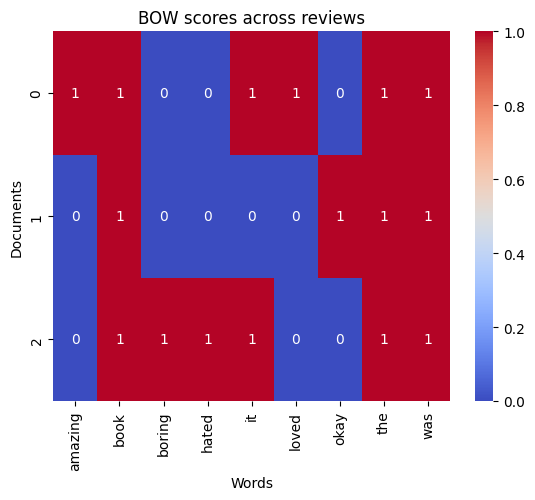

In [ ]:
bow_df = pd .DataFrame(bow_matrix.toarray(), columns=vectorizer.get_feature_names_out())
sns.heatmap(bow_df, annot=True, cmap='coolwarm')
plt.title('BOW scores across reviews')
plt.xlabel('Words')
plt.ylabel('Documents')
plt.show()

## Word Embeddings

In [ ]:
!pip install gensim


In [ ]:
import gensim.downloader as api

model = api.load('glove-wiki-gigaword-50') # glove is model name , wiki is wikipedia data model trained on and 100 is the number of dimensions in the embeddings vector

[==================================================] 100.0% 66.0/66.0MB downloaded


In [ ]:
print(model['book'])

[-0.0076543  0.93456   -0.73189   -0.55162    0.76977    0.35925
 -1.1365    -1.1632     0.34214    0.29145   -0.8711     0.9197
 -0.47069   -0.22834    1.4777    -0.81714   -0.17466   -0.51093
 -0.28354    0.23292    0.71832    0.23414    0.49443    0.35483
  0.76889   -1.4374    -1.7457    -0.28994   -0.10156   -0.36959
  2.5502    -1.0581    -0.049416  -0.25524   -0.63303    0.02671
 -0.18733    0.20206   -0.26288   -0.41418    0.83473   -0.14227
 -0.28125    0.098155  -0.17096    0.52408    0.31851   -0.089847
 -0.27223   -0.0088736]


In [ ]:
print(model.similarity('book','document'))

0.6154337


In [ ]:
model.most_similar('book',topn=3)

[('books', 0.9047631025314331),
 ('story', 0.8662747144699097),
 ('novel', 0.8550738096237183)]

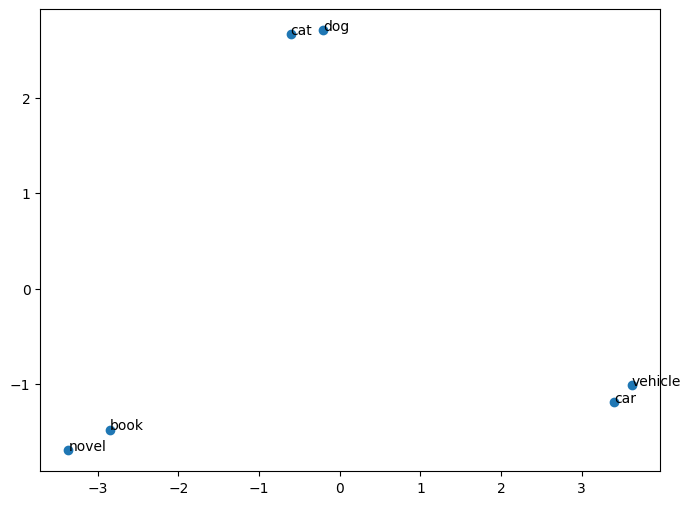

In [ ]:
from sklearn.decomposition import PCA

words = ['cat','dog','book','novel','car','vehicle']

word_vectors = [model[word] for word in words]

pca = PCA(n_components=2)
word_vectors_2d = pca.fit_transform(word_vectors)

plt.figure(figsize=(8,6))
plt.scatter(word_vectors_2d[:,0],word_vectors_2d[:,1])
for i,word in enumerate(words):
    plt.annotate(word,xy=(word_vectors_2d[i,0],word_vectors_2d[i,1])) # the 2 features we're plotting for each word
plt.show()

In [ ]:
from transformers import pipeline

In [ ]:
classification_pipeline = pipeline(
    task='sentiment-analysis', # or text-classification
    model='distilbert/distilbert-base-uncased-finetuned-sst-2-english',
)
result = classification_pipeline('I loved the book. It was amazing.')
print(result) # label with a confidence score

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9998883008956909}]


In [ ]:
texts = [
    'I loved the book. It was amazing.',
    'The book was okay.',
    'I hated the book , it was boring.',
    'Good job runining the project.',
    'You have to be sued for how good this cake is.',
    'Brilliant,just what our team missed ... another rookie to teach '
]

true_labels = ['POSITIVE','NEGATIVE','NEGATIVE',' NEGATIVE','POSITIVE','NEGATIVE']
results = classification_pipeline(texts)

In [ ]:
predicted_labels = [result['label'] for result in results]
predicted_labels

['POSITIVE', 'POSITIVE', 'NEGATIVE', 'POSITIVE', 'NEGATIVE', 'POSITIVE']

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(true_labels,predicted_labels)
print(f'Accuracy: {accuracy}')

Accuracy: 0.3333333333333333


## Zero-shot classification pipeline where the model assigns the text to labels it has not seen before

In [ ]:
zero_shot_classifier = pipeline(
    task='zero-shot-classification',
    model='MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli',
)
candidate_labels = ['sports','health','politics']
text = 'The national football team won the cup yesterday'
results = zero_shot_classifier(text,candidate_labels)
results

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

{'sequence': 'The national football team won the cup yesterday',
 'labels': ['sports', 'health', 'politics'],
 'scores': [0.9983682036399841, 0.00119669025298208, 0.0004351088427938521]}

## Question Natural Language Inference (QNLI) where it determines an answer to a question can be found in a document or not

In [ ]:
qnli_pipeline = pipeline(
    task = 'text-classification',
    model = 'cross-encoder/qnli-electra-base',
)

passage = 'Penguins are found primarly in the Southern Hemishphere'
question = 'Where do penguins live ?'
result = qnli_pipeline({
    'text':question,
    'text_pair':passage,
})
print(result)


config.json:   0%|          | 0.00/771 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

{'label': 'LABEL_0', 'score': 0.9983616471290588}


In [ ]:
passage = 'Penguins are found primarly in the Southern Hemishphere'
question = 'What is the capital of France?'
result = qnli_pipeline({
    'text':question,
    'text_pair':passage,
})
print(result)

{'label': 'LABEL_0', 'score': 0.001584464218467474}


## Question Similarity with models trained on QQP Quora Question Pairs dataset

In [ ]:
qqp_pipeline = pipeline(
    task='text-classification',
    model = 'textattack/bert-base-uncased-QQP',
)

question1 = "How can I learn python?"
question2 = "What is the best way to learn python?"

result = qqp_pipeline({"text": question1, "text_pair": question2})
print(result) # label 1 means simialr , 0 not simialr each with a score

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'label': 'LABEL_1', 'score': 0.8079021573066711}


In [ ]:
question1 = "How can I learn python?"
question2 = "What is the capital of France?"

result = qqp_pipeline({"text": question1, "text_pair": question2})
print(result) # label 1 means simialr , 0 not simialr each with a score

{'label': 'LABEL_0', 'score': 0.9999338388442993}


## Asessing Grammatical Correctness done with models trained on Corpus of lingustic Acceptability dataset COLA

In [ ]:
cola_pipeline = pipeline(
    task = 'text-classification',
     model = 'textattack/bert-base-uncased-CoLA',
)
result = cola_pipeline('The cat sat on the mat.') #label 0 means not correct  , 1 correct
print(result)

config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[{'label': 'LABEL_1', 'score': 0.982284665107727}]


In [ ]:
result = cola_pipeline('The cat he be playing weird stuff lowkey man what is this.') #label 0 means not correct  , 1 correct
print(result)

[{'label': 'LABEL_0', 'score': 0.9598269462585449}]


## Token Classification where we assign labels to individual tokens within a sentence , this is the foundation of 2 NLP tasks
## 1. Named Entity Recognition ( NER )
## 2. Part of Speech tagging ( POS )

## Named Entity Recognition ( NER ) identifies entities like names, locations , organizations , dates and more

In [ ]:
from transformers import pipeline

ner = pipeline(
    task='ner',
    model='dslim/bert-base-NER',
    aggregation_strategy='simple',  # corrected from grouped_entites
)
ner_result = ner('Omar Marmoush plays for the Egyptian national football team')
print(ner_result)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'entity_group': 'PER', 'score': np.float32(0.998096), 'word': 'Omar Marmoush', 'start': 0, 'end': 13}, {'entity_group': 'MISC', 'score': np.float32(0.9997445), 'word': 'Egyptian', 'start': 28, 'end': 36}]


## Part of Speech tagging ( POS) assigns grammatical roles ( noun , verb ,etc ) to each word in a sentence

In [ ]:
pos_pipeline = pipeline(
    task='token-classification',
    model='vblagoje/bert-english-uncased-finetuned-pos',
    aggregation_strategy='simple',
)
pos_result = pos_pipeline('Omar Marmoush plays for the Egyptian national football team')
print(pos_result)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: vblagoje/bert-english-uncased-finetuned-pos
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'entity_group': 'PROPN', 'score': np.float32(0.998352), 'word': 'omar marmoush', 'start': 0, 'end': 13}, {'entity_group': 'VERB', 'score': np.float32(0.9991097), 'word': 'plays', 'start': 14, 'end': 19}, {'entity_group': 'ADP', 'score': np.float32(0.99942315), 'word': 'for', 'start': 20, 'end': 23}, {'entity_group': 'DET', 'score': np.float32(0.9993318), 'word': 'the', 'start': 24, 'end': 27}, {'entity_group': 'ADJ', 'score': np.float32(0.7336132), 'word': 'egyptian national', 'start': 28, 'end': 45}, {'entity_group': 'NOUN', 'score': np.float32(0.9594331), 'word': 'football team', 'start': 46, 'end': 59}]


## Question Answering
## 1. Extractive QA where answer is directly copied from passage
## 2. Abstractive QA where model answers in natural language tone

In [ ]:
# Abstractive

from transformers import pipeline

# Using a text-generation pipeline with an instruct/chat model as recommended by Hugging Face v5
qa_generator = pipeline(
    task='text-generation',
    model='HuggingFaceTB/SmolLM2-1.7B-Instruct',
)

context = "The Amazon rainforest is the largest tropical rainforest in the world, covering parts of Peru, Brazil, and Colombia."
question = 'Where is the Amazon rainforest located?'

messages = [
    {
        "role": "user",
        "content": f"Answer the following question based on the context provided.\n\nContext: {context}\n\nQuestion: {question}"
    }
]

# Generate the answer
results = qa_generator(messages, max_new_tokens=50, clean_up_tokenization_spaces=True)
print(results[0]['generated_text'][-1]['content'])

Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

The Amazon rainforest is located in parts of Peru, Brazil, and Colombia.


In [ ]:
#Extractive QA
import torch
from transformers import AutoTokenizer, AutoModelForQuestionAnswering

# Explicitly load model and tokenizer for extractive QA in transformers v5
model_name = "deepset/roberta-base-squad2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForQuestionAnswering.from_pretrained(model_name)

# Expanded context with significantly more detailed information
context = """The Amazon rainforest is the largest tropical rainforest in the world, covering parts of Peru, Brazil, and Colombia."""

question = "Where is the Amazon rainforest located?"

# Encode the input text
inputs = tokenizer(question, context, return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs)

# Extract answer span using logits
answer_start = torch.argmax(outputs.start_logits)
answer_end = torch.argmax(outputs.end_logits) + 1

# Decode and output the extracted token span
answer = tokenizer.convert_tokens_to_string(tokenizer.convert_ids_to_tokens(inputs["input_ids"][0][answer_start:answer_end]))
print("Extracted Answer:", answer)

tokenizer_config.json:   0%|          | 0.00/79.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  496MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Extracted Answer:  Peru, Brazil, and Colombia


## Sequence Generation produces new text based on a given input

## Text Summarization where it condenses long documents into shorter versions highlighting key details

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Explicitly load the model and tokenizer for summarization in v5
model_name = 'cnicu/t5-small-booksum'
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

context = """The Amazon rainforest is the largest tropical rainforest in the world, spanning an incredible 5.5 million square kilometers.
It covers parts of nine nations, with the largest portions situated in Brazil (60%), Peru (13%), and Colombia (10%),
as well as smaller areas in Venezuela, Ecuador, Bolivia, Guyana, Suriname, and French Guiana. Often referred to as the
'lungs of the planet,' the Amazon represents over half of our planet's remaining rainforests and houses an unparalleled
biodiversity. It is home to approximately 16,000 tree species, 40,000 plant species, and millions of animal species,
many of which are still undocumented. Furthermore, its massive vegetation plays a crucial role in stabilizing the global
climate by absorbing billions of tons of carbon dioxide from the atmosphere every year."""

# Add T5 prompt prefix and tokenize
inputs = tokenizer("summarize: " + context, return_tensors="pt", max_length=512, truncation=True)

# Generate summary ids
summary_ids = model.generate(inputs["input_ids"], max_length=150, min_length=30, length_penalty=2.0, num_beams=4, early_stopping=True)

# Decode and print the summary
summary = tokenizer.decode(summary_ids[0], skip_special_tokens=True)
print(summary)

tokenizer_config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.79k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  242MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

the Amazon rainforest covers parts of nine nations, with the largest portions situated in Brazil (60%), Peru (13%), and Colombia (10%), as well as smaller areas in Venezuela, Ecuador, Bolivia, Guyana, Suriname, and French Guiana. The Amazon is home to approximately 16,000 tree species, 40,000 plant species, and millions of animal species, many of which are still undocumented.


## Text translation

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Explicitly load translation model and tokenizer for English to Arabic
model_name = "Helsinki-NLP/opus-mt-en-ar"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

english_text = "The Amazon rainforest is the largest tropical rainforest in the world."

# Tokenize and translate
inputs = tokenizer(english_text, return_tensors="pt", padding=True)
translated_tokens = model.generate(**inputs)

# Decode translation
arabic_translation = tokenizer.decode(translated_tokens[0], skip_special_tokens=True)
print("Original:", english_text)
print("Translation (Arabic):", arabic_translation)

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/801k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/917k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.12M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  308MB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Original: The Amazon rainforest is the largest tropical rainforest in the world.
Translation (Arabic): غابات الأمازون المطيرة هي أكبر غابات مطيرة مدارية في العالم.


## Language Modeling where we predict the next word in a given sequence

In [ ]:
generator = pipeline(
    task = 'text-generation',
    model = 'distilgpt2',
)
prompt = "In the cold rainy November dusk,"
result = generator(prompt,max_length=100,num_return_sequences=3)
print(result[0]['generated_text'])
print(result[1]['generated_text'])
print(result[2]['generated_text'])

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

In the cold rainy November dusk, the police showed up around 7:30 p.m. in the same rented trailer on the same side of the street to take a closer look at the cars. The officer told them to turn off their lights and turn off their lights.













































In the cold rainy November dusk, they will make a trek across the river in a bid to catch the rarest of the winter.









































































In the cold rainy November dusk, we heard a loud, clattering noise in the forest. The birds did not respond, but they did.




"We heard the sounds of a massive tree blowing up," I said. "The sound of a huge tree blowing up."
"It's not a huge tree, it's just a small tree."
"It's a small tree."
"Then you hear something like that," I said.
"It's a
